# 03 - Baseline Models and Model Selection

## Predicting Credit Card Fraud

### Objectives

- Establish a Dummy Classifier baseline.
- Train different classification algorithms.
- Compare linear, tree-based and ensemble models.
- Evaluate ROC-AUC and Average Precision.
- Analyze Precision, Recall and F1-Score.
- Select the most promising models.

### Evaluation strategy

- Stratified Train/Validation split.
- 80% Training.
- 20% Validation.
- Random State: 42.

No resampling or class weighting will be applied
during this initial model comparison.

In [34]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import time

from pathlib import Path

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, RobustScaler

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 5)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")

In [35]:
# Locate data directory
possible_paths = [
    Path.cwd() / "data" / "raw",
    Path.cwd().parent / "data" / "raw"
]

DATA_DIR = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_DIR is None:
    raise FileNotFoundError("Could not locate data/raw directory")

# Load dataset
train = pd.read_csv(DATA_DIR / "train.csv")

print("Train shape:", train.shape)

Train shape: (699960, 26)


In [36]:
TARGET = "is_fraud"
ID_COL = "id"

# Separate features and target
X = train.drop(
    columns=[TARGET, ID_COL]
).copy()

y = train[TARGET].astype("int8").copy()

print("X:", X.shape)
print("y:", y.shape)

display(y.value_counts(normalize=True) * 100)

X: (699960, 24)
y: (699960,)


is_fraud
0   98.33005
1    1.66995
Name: proportion, dtype: float64

In [37]:
# Boolean features
boolean_cols = [
    col for col in X.columns
    if pd.api.types.is_bool_dtype(X[col])
]

# Categorical features
categorical_cols = [
    col for col in X.columns
    if (
        pd.api.types.is_string_dtype(X[col])
        or pd.api.types.is_object_dtype(X[col])
        or isinstance(X[col].dtype, pd.CategoricalDtype)
    )
]

# Numerical features
numeric_cols = [
    col for col in X.columns
    if (
        pd.api.types.is_numeric_dtype(X[col])
        and not pd.api.types.is_bool_dtype(X[col])
    )
]

print("Numerical:", len(numeric_cols))
print("Categorical:", len(categorical_cols))
print("Boolean:", len(boolean_cols))

Numerical: 13
Categorical: 5
Boolean: 6


In [38]:
def create_preprocessor(scale_numeric=True):

    # Numerical features
    numerical_transformer = (
        RobustScaler()
        if scale_numeric
        else "passthrough"
    )

    # Categorical features
    try:
        categorical_transformer = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
            dtype=np.float32
        )

    except TypeError:
        categorical_transformer = OneHotEncoder(
            handle_unknown="ignore",
            sparse=False,
            dtype=np.float32
        )

    # Combined preprocessing
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                numerical_transformer,
                numeric_cols
            ),
            (
                "cat",
                categorical_transformer,
                categorical_cols
            ),
            (
                "bool",
                "passthrough",
                boolean_cols
            )
        ],
        remainder="drop"
    )

    return preprocessor

In [39]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)

print("\ny_train:", y_train.shape)
print("y_valid:", y_valid.shape)

print("\nFraud percentage:")
print(f"Train: {y_train.mean() * 100:.4f}%")
print(f"Validation: {y_valid.mean() * 100:.4f}%")

X_train: (559968, 24)
X_valid: (139992, 24)

y_train: (559968,)
y_valid: (139992,)

Fraud percentage:
Train: 1.6699%
Validation: 1.6701%


In [40]:
models_config = {

    "Dummy Classifier": {
        "estimator": DummyClassifier(
            strategy="prior"
        ),
        "scale_numeric": None
    },

    "Logistic Regression": {
        "estimator": LogisticRegression(
            solver="lbfgs",
            max_iter=500,
            random_state=42
        ),
        "scale_numeric": True
    },

    "Decision Tree": {
        "estimator": DecisionTreeClassifier(
            max_depth=12,
            min_samples_leaf=20,
            random_state=42
        ),
        "scale_numeric": False
    },

    "Random Forest": {
        "estimator": RandomForestClassifier(
            n_estimators=100,
            max_depth=16,
            min_samples_leaf=10,
            max_features="sqrt",
            n_jobs=-1,
            random_state=42
        ),
        "scale_numeric": False
    },

    "Extra Trees": {
        "estimator": ExtraTreesClassifier(
            n_estimators=100,
            max_depth=16,
            min_samples_leaf=10,
            max_features="sqrt",
            n_jobs=-1,
            random_state=42
        ),
        "scale_numeric": False
    },

    "Hist Gradient Boosting": {
        "estimator": HistGradientBoostingClassifier(
            max_iter=100,
            learning_rate=0.1,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=42
        ),
        "scale_numeric": False
    },

    "XGBoost": {
        "estimator": XGBClassifier(
            objective="binary:logistic",
            eval_metric="auc",
            n_estimators=200,
            learning_rate=0.1,
            max_depth=6,
            min_child_weight=5,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            tree_method="hist",
            n_jobs=-1,
            random_state=42,
            verbosity=0
        ),
        "scale_numeric": False
    },

    "LightGBM": {
        "estimator": LGBMClassifier(
            objective="binary",
            n_estimators=200,
            learning_rate=0.1,
            num_leaves=31,
            max_depth=-1,
            min_child_samples=20,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            n_jobs=-1,
            random_state=42,
            verbosity=-1
        ),
        "scale_numeric": False
    },

}

print("Models configured:", len(models_config))

for name in models_config:
    print("-", name)

Models configured: 8
- Dummy Classifier
- Logistic Regression
- Decision Tree
- Random Forest
- Extra Trees
- Hist Gradient Boosting
- XGBoost
- LightGBM


In [41]:
fitted_models = {}
valid_probabilities = {}
model_results = []

for name, config in models_config.items():

    print(f"\nTraining: {name}")

    estimator = config["estimator"]
    scale_numeric = config["scale_numeric"]

    # Dummy model does not require preprocessing
    if scale_numeric is None:

        model = estimator

        X_fit = np.zeros(
            (len(X_train), 1),
            dtype=np.float32
        )

        X_eval = np.zeros(
            (len(X_valid), 1),
            dtype=np.float32
        )

    else:

        # Preprocessing + classifier pipeline
        model = Pipeline(
            steps=[
                (
                    "preprocessing",
                    create_preprocessor(scale_numeric)
                ),
                (
                    "classifier",
                    estimator
                )
            ]
        )

        X_fit = X_train
        X_eval = X_valid

    # Training
    start_time = time.perf_counter()

    model.fit(X_fit, y_train)

    fit_time = time.perf_counter() - start_time

    # Prediction probabilities
    start_time = time.perf_counter()

    y_proba = model.predict_proba(X_eval)[:, 1]

    predict_time = time.perf_counter() - start_time

    # Default classification threshold
    y_pred = (y_proba >= 0.5).astype("int8")

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_valid,
        y_pred,
        labels=[0, 1]
    ).ravel()

    # Evaluation metrics
    roc_auc = roc_auc_score(y_valid, y_proba)

    avg_precision = average_precision_score(
        y_valid,
        y_proba
    )

    accuracy = accuracy_score(y_valid, y_pred)

    precision = precision_score(
        y_valid,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_valid,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_valid,
        y_pred,
        zero_division=0
    )

    # Store models and probabilities
    fitted_models[name] = model
    valid_probabilities[name] = y_proba

    model_results.append({
        "model": name,
        "roc_auc": roc_auc,
        "average_precision": avg_precision,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "true_negatives": tn,
        "predicted_frauds": int(y_pred.sum()),
        "fit_time_seconds": fit_time,
        "predict_time_seconds": predict_time
    })

    print(f"ROC-AUC: {roc_auc:.5f}")
    print(f"Average Precision: {avg_precision:.5f}")
    print(f"Fit time: {fit_time:.2f} seconds")
    print("Model completed.")


Training: Dummy Classifier
ROC-AUC: 0.50000
Average Precision: 0.01670
Fit time: 0.01 seconds
Model completed.

Training: Logistic Regression
ROC-AUC: 0.94028
Average Precision: 0.49698
Fit time: 3.51 seconds
Model completed.

Training: Decision Tree
ROC-AUC: 0.89131
Average Precision: 0.38568
Fit time: 5.92 seconds
Model completed.

Training: Random Forest
ROC-AUC: 0.93209
Average Precision: 0.46195
Fit time: 15.16 seconds
Model completed.

Training: Extra Trees
ROC-AUC: 0.92693
Average Precision: 0.44493
Fit time: 19.07 seconds
Model completed.

Training: Hist Gradient Boosting
ROC-AUC: 0.94357
Average Precision: 0.48925
Fit time: 4.36 seconds
Model completed.

Training: XGBoost
ROC-AUC: 0.94386
Average Precision: 0.50234
Fit time: 3.23 seconds
Model completed.

Training: LightGBM
ROC-AUC: 0.94423
Average Precision: 0.50289
Fit time: 1.78 seconds
Model completed.


In [42]:
results_df = pd.DataFrame(model_results)

results_df = results_df.set_index("model")

results_df = results_df.sort_values(
    by="roc_auc",
    ascending=False
)

display(results_df)

,roc_auc,average_precision,accuracy,precision,recall,f1_score,true_positives,false_positives,false_negatives,true_negatives,predicted_frauds,fit_time_seconds,predict_time_seconds
model,,,,,,,,,,,,,
LightGBM,0.94423,0.50289,0.98666,0.74557,0.30582,0.43373,715,244,1623,137410,959,1.77673,0.25843
XGBoost,0.94386,0.50234,0.98676,0.74520,0.31523,0.44304,737,252,1601,137402,989,3.22506,0.18042
Hist Gradient Boosting,0.94357,0.48925,0.98641,0.72065,0.30453,0.42814,712,276,1626,137378,988,4.36145,0.40108
Logistic Regression,0.94028,0.49698,0.98681,0.76541,0.30282,0.43396,708,217,1630,137437,925,3.50860,0.11460
Random Forest,0.93209,0.46195,0.98505,0.92683,0.11377,0.20267,266,21,2072,137633,287,15.16140,0.19804
Extra Trees,0.92693,0.44493,0.98453,0.93878,0.07870,0.14522,184,12,2154,137642,196,19.07324,0.19918
Decision Tree,0.89131,0.38568,0.98513,0.63389,0.25920,0.36794,606,350,1732,137304,956,5.92423,0.11261
Dummy Classifier,0.50000,0.01670,0.98330,0.00000,0.00000,0.00000,0,0,2338,137654,0,0.00864,0.00152


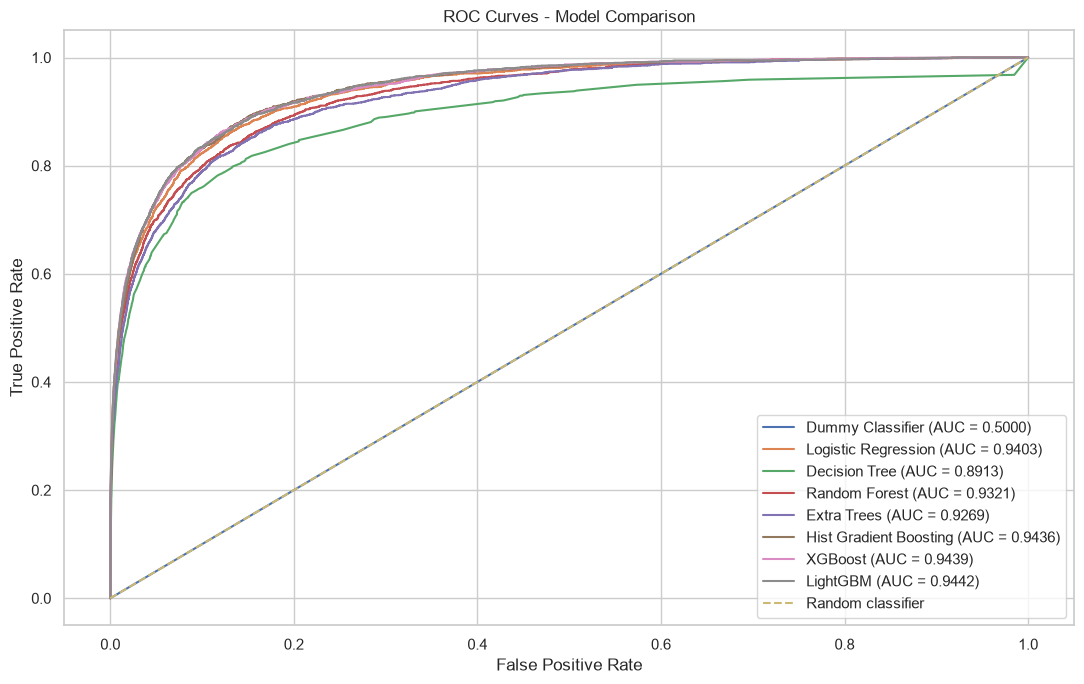

In [43]:
plt.figure(figsize=(11, 7))

for name, y_proba in valid_probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_valid,
        y_proba
    )

    auc = roc_auc_score(y_valid, y_proba)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.title("ROC Curves - Model Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.tight_layout()
plt.show()

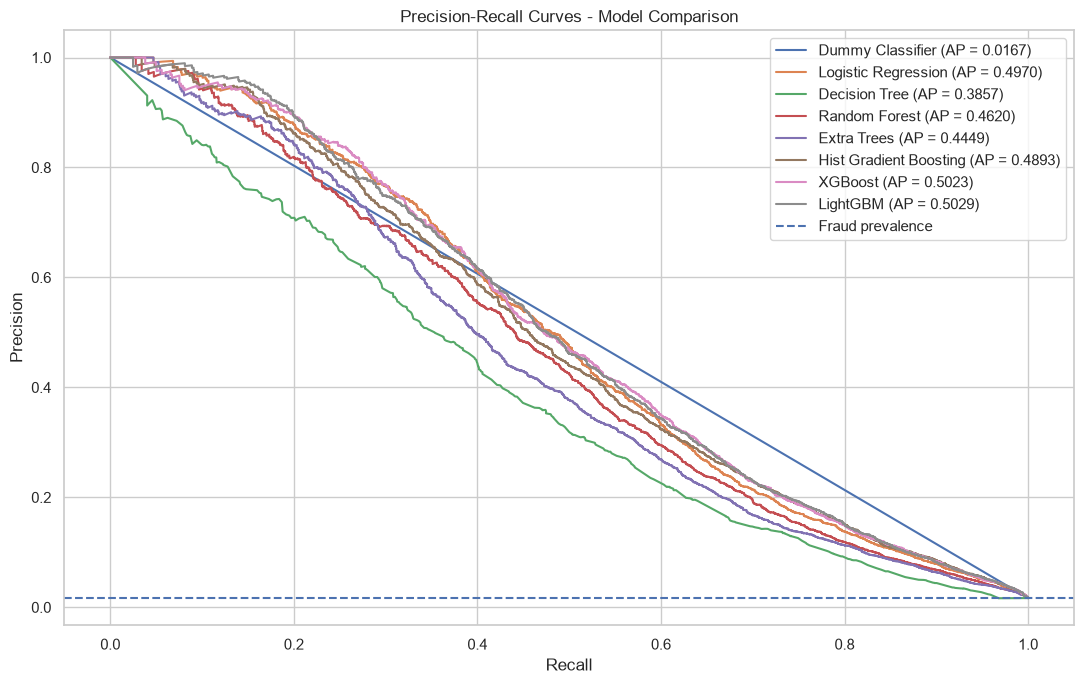

In [44]:
plt.figure(figsize=(11, 7))

for name, y_proba in valid_probabilities.items():

    precision_values, recall_values, thresholds = (
        precision_recall_curve(y_valid, y_proba)
    )

    ap = average_precision_score(
        y_valid,
        y_proba
    )

    plt.plot(
        recall_values,
        precision_values,
        label=f"{name} (AP = {ap:.4f})"
    )

plt.axhline(
    y=y_valid.mean(),
    linestyle="--",
    label="Fraud prevalence"
)

plt.title("Precision-Recall Curves - Model Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend()
plt.tight_layout()
plt.show()

Top 3 models by ROC-AUC:
['LightGBM', 'XGBoost', 'Hist Gradient Boosting']


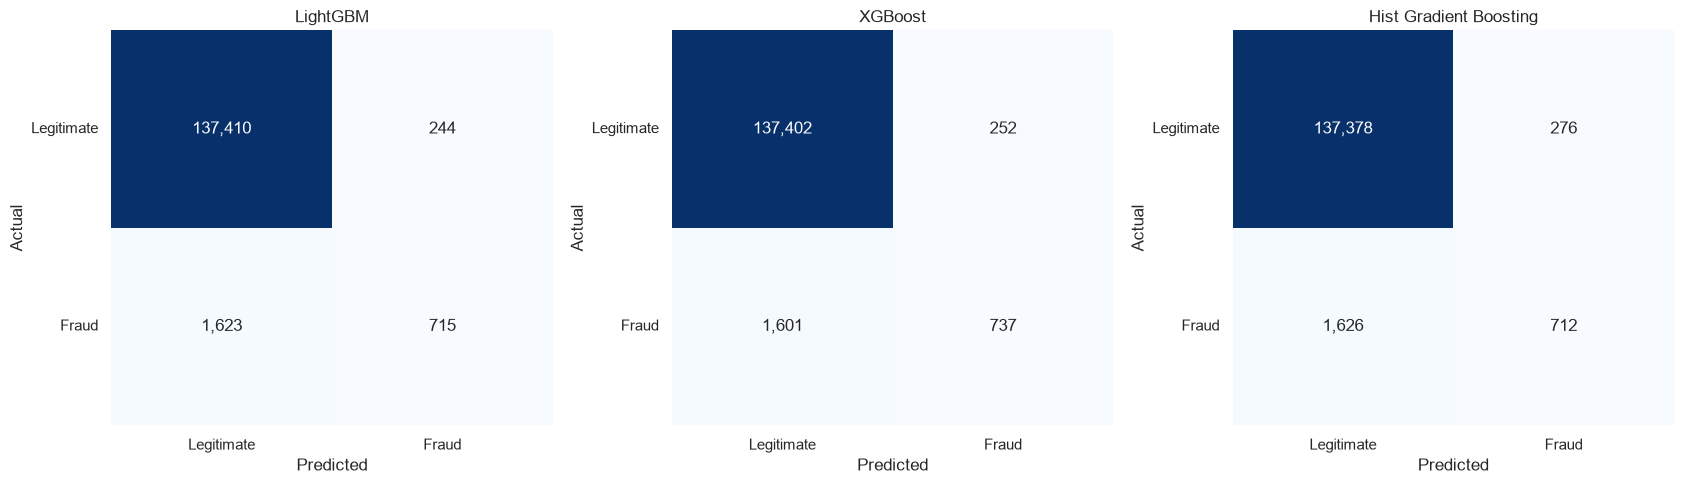

In [45]:
top_3_models = results_df.head(3).index.tolist()

print("Top 3 models by ROC-AUC:")
print(top_3_models)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)

for ax, name in zip(axes, top_3_models):

    y_pred = (
        valid_probabilities[name] >= 0.5
    ).astype("int8")

    cm = confusion_matrix(
        y_valid,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt=",",
        cmap="Blues",
        cbar=False,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticklabels(["Legitimate", "Fraud"])
    ax.set_yticklabels(["Legitimate", "Fraud"], rotation=0)

plt.tight_layout()
plt.show()

In [46]:
model_ranking = results_df[
    [
        "roc_auc",
        "average_precision",
        "precision",
        "recall",
        "f1_score",
        "fit_time_seconds"
    ]
].copy()

model_ranking["roc_rank"] = (
    model_ranking["roc_auc"].rank(ascending=False)
)

model_ranking["ap_rank"] = (
    model_ranking["average_precision"].rank(ascending=False)
)

model_ranking["combined_rank"] = (
    model_ranking["roc_rank"] +
    model_ranking["ap_rank"]
)

model_ranking = model_ranking.sort_values(
    "combined_rank"
)

display(model_ranking)

,roc_auc,average_precision,precision,recall,f1_score,fit_time_seconds,roc_rank,ap_rank,combined_rank
model,,,,,,,,,
LightGBM,0.94423,0.50289,0.74557,0.30582,0.43373,1.77673,1.00000,1.00000,2.00000
XGBoost,0.94386,0.50234,0.74520,0.31523,0.44304,3.22506,2.00000,2.00000,4.00000
Hist Gradient Boosting,0.94357,0.48925,0.72065,0.30453,0.42814,4.36145,3.00000,4.00000,7.00000
Logistic Regression,0.94028,0.49698,0.76541,0.30282,0.43396,3.50860,4.00000,3.00000,7.00000
Random Forest,0.93209,0.46195,0.92683,0.11377,0.20267,15.16140,5.00000,5.00000,10.00000
Extra Trees,0.92693,0.44493,0.93878,0.07870,0.14522,19.07324,6.00000,6.00000,12.00000
Decision Tree,0.89131,0.38568,0.63389,0.25920,0.36794,5.92423,7.00000,7.00000,14.00000
Dummy Classifier,0.50000,0.01670,0.00000,0.00000,0.00000,0.00864,8.00000,8.00000,16.00000


# Baseline Models - Conclusions

## 1. Model Comparison

- Best ROC-AUC model: LightGBM (0.94423).
- Best Average Precision model: LightGBM (0.50289).
- Best F1-Score model: XGBoost (0.44304).
- Overall best candidates: LightGBM and XGBoost.

## 2. Linear vs Tree-Based Models

- Logistic Regression achieved a competitive ROC-AUC (0.94028).
- Decision Tree showed lower predictive performance.
- Random Forest and Extra Trees achieved high precision but low recall.
- HistGradientBoosting obtained good overall results.
- XGBoost and LightGBM achieved the best overall performance.

## 3. Imbalanced Classification

- Default threshold: 0.5.
- Fraud detection recall remains around 30-32%.
- Most fraudulent transactions are still classified as legitimate.
- False positive rates remain relatively low.
- Class imbalance represents an important limitation.

## 4. Model Selection

Selected models:

- LightGBM: best ROC-AUC and Average Precision.
- XGBoost: best F1-Score and Recall among the top three.
- Logistic Regression: competitive linear baseline.
- HistGradientBoosting: additional boosting candidate.

## 5. Limitations

- No class balancing applied.
- No hyperparameter tuning applied.
- Default classification threshold of 0.5.
- KNN was tested on a representative sample but
  achieved considerably lower performance.
- Potential data leakage concerning
  `is_ai_generated_scam_attempt` still requires investigation.

## 6. Next Steps

- Evaluate class weighting.
- Investigate resampling techniques.
- Compare model performance under different imbalance strategies.
- Investigate classification threshold optimization.